<a href="https://colab.research.google.com/github/quarcs-lab/geo4bolivia/blob/main/notebooks/eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exploratory data analysis of multidimensional poverty in Bolivia

Part of the [GeoDevelopment Observatory of Bolivia](https://quarcs-lab.github.io/geo4bolivia/).

This notebook explores how multidimensional poverty varies across Bolivia's 343 municipalities and indigenous autonomies, how it changed between the 2012 and 2024 censuses, and how it relates to population and night-time lights. All data come from the `geo4bolivia` package.

1. **Load the data** with `geo4bolivia`
2. **Descriptive statistics**, for the country and by department, in both periods
3. **Regional differences**: how poverty is distributed across departments
4. **Change, 2012-2024**: where poverty fell most
5. **Population and poverty**: are the most populous municipalities less poor?
6. **Night-time lights and poverty**: can lights from space help predict poverty?

## 0. Setup

In Google Colab the next cell installs the package and the mapping library (a few seconds). Locally, `uv sync` has installed them already.

In [1]:
import importlib.util

missing = [p for p in ["geo4bolivia", "mapclassify"] if importlib.util.find_spec(p) is None]
if missing:
    pkgs = " ".join(missing)
    !pip install -q {pkgs}

In [2]:
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.io as pio

import geo4bolivia as geo

if "google.colab" not in sys.modules:
    pio.renderers.default = "plotly_mimetype+notebook_connected"   # keeps the saved notebook small

sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", message="Numba not installed")   # mapclassify works without it

## 1. Load the data

| Variable | Dataset | Periods | Meaning |
| --- | --- | --- | --- |
| `sdg1_2_mpi` | `sdg01` | 2012, 2024 | Multidimensional Poverty Index (0–1; **higher = poorer**), from the censuses |
| `population` | `sdg` | 2012, 2024 | Census population |
| `ln_t400NTLpc` | `ntl` | 2012–2020 | Long-run trend (HP filter) of the log of night-time lights per capita |

The poverty index comes from the [Atlas de los ODS en Bolivia 2026](https://atlasods.sdsnbolivia.org/) (Andersen & Argandoña, SDSN Bolivia), which computes it from the 2012 and 2024 Population and Housing Censuses for all 343 units. Night-time lights were computed on the older 339-unit map, so they cover **333 units**: the six municipalities that have since lost territory (Colquechaca, Mizque, Porco, Tomave, San Ignacio and Santa Ana) and the four units created after 2012 have no values. Section 6 uses those 333.

We build a long table (one row per unit and period) for the plots, and a wide GeoDataFrame (one row per unit) for the maps.

In [3]:
YEARS = [2012, 2024]

mpi = geo.load("sdg01", variables="sdg1_2_mpi")
census = geo.load("sdg", variables="population")

# department and province of each municipality, from the units table
units = geo.units()
names = units.set_index("geo_id")["name"]
parents = units.loc[units["scale"] == "municipality", ["geo_id", "name", "department_id", "province_id"]]
parents["department"] = parents["department_id"].map(names)
parents["province"] = parents["province_id"].map(names)
parents = parents[["geo_id", "name", "province", "department"]]

long = mpi.merge(census, on=["geo_id", "year"]).merge(parents, on="geo_id")
long["rank_mpi"] = long.groupby("year")["sdg1_2_mpi"].rank(ascending=False, method="min").astype(int)  # 1 = poorest
long["period"] = long["year"].astype(str)

wide = long.pivot(index="geo_id", columns="year", values=["sdg1_2_mpi", "population", "rank_mpi"])
wide.columns = [f"{v}_{y}" for v, y in wide.columns]
wide = wide.astype({f"{v}_{y}": int for v in ["population", "rank_mpi"] for y in YEARS})
wide["mpi_change"] = wide["sdg1_2_mpi_2024"] - wide["sdg1_2_mpi_2012"]

lights = geo.load("ntl", variables="ln_t400NTLpc", years=2012)[["geo_id", "ln_t400NTLpc"]]

gdf = (geo.boundaries("municipality")[["geo_id", "geometry"]]
       .merge(parents, on="geo_id").merge(wide.reset_index(), on="geo_id")
       .merge(lights, on="geo_id", how="left"))
print(long.shape, gdf.shape, f"units with lights: {gdf['ln_t400NTLpc'].notna().sum()}")
gdf.drop(columns="geometry").head()

(686, 9) (343, 13) units with lights: 333


,geo_id,name,province,department,sdg1_2_mpi_2012,sdg1_2_mpi_2024,population_2012,population_2024,rank_mpi_2012,rank_mpi_2024,mpi_change,ln_t400NTLpc
0,BO-01-01-01,Azurduy,Azurduy,Chuquisaca,0.512,0.187,10652,7903,3,7,-0.325,11.048312
1,BO-01-01-02,Tarvita,Azurduy,Chuquisaca,0.452,0.133,14261,16812,16,29,-0.319,12.329279
2,BO-01-02-01,Villa Serrano,Belisario Boeto,Chuquisaca,0.267,0.056,11161,9107,122,160,-0.211,12.815315
3,BO-01-03-01,Huacareta,Hernando Siles,Chuquisaca,0.346,0.071,8349,7200,49,112,-0.275,12.018971
4,BO-01-03-02,Monteagudo,Hernando Siles,Chuquisaca,0.212,0.043,24303,24546,195,210,-0.169,14.603350


Labels for the plots, and a fixed colour for each department and period:

In [4]:
labels = {
    "sdg1_2_mpi": "Multidimensional poverty index",
    "sdg1_2_mpi_2012": "Multidimensional poverty index (2012)",
    "sdg1_2_mpi_2024": "Multidimensional poverty index (2024)",
    "mpi_change": "Change in MPI, 2012-2024",
    "population": "Census population",
    "population_2024": "Census population (2024)",
    "ln_t400NTLpc": "Log night-time lights per capita (trend, 2012)",
    "rank_mpi_2024": "Poverty rank in 2024 (1 = poorest)",
    "department": "Department",
    "name": "Municipality",
}
departments = sorted(gdf["department"].unique())
palette = dict(zip(departments, sns.color_palette("tab10", len(departments))))
period_palette = {"2012": "tab:orange", "2024": "tab:blue"}

## 2. Descriptive statistics

- What do we know about the centre and dispersion of poverty, and how did they change?

In [5]:
gdf[["sdg1_2_mpi_2012", "sdg1_2_mpi_2024", "mpi_change", "population_2012", "population_2024"]].describe().round(3)

,sdg1_2_mpi_2012,sdg1_2_mpi_2024,mpi_change,population_2012,population_2024
count,343.000,343.000,343.000,343.000,343.000
mean,0.234,0.063,-0.171,29329.026,33133.915
std,0.106,0.044,0.071,107270.842,116499.084
min,0.018,0.003,-0.402,509.000,875.000
25%,0.153,0.030,-0.225,5945.000,6691.500
50%,0.227,0.053,-0.169,10647.000,12296.000
75%,0.306,0.083,-0.118,19544.000,21083.000
max,0.563,0.296,-0.015,1444425.000,1610982.000


In [6]:
by_dep = long.groupby(["department", "year"])["sdg1_2_mpi"].agg(["count", "mean", "median", "std", "min", "max"])
by_dep = by_dep.unstack("year").round(3)
by_dep.sort_values(("mean", 2012), ascending=False)

count        mean        median           std           min         \
year        2012 2024   2012   2024   2012   2024   2012   2024   2012   2024   
department                                                                      
Chuquisaca    29   29  0.323  0.090  0.317  0.074  0.105  0.054  0.071  0.014   
Pando         15   15  0.315  0.068  0.336  0.056  0.105  0.038  0.112  0.019   
Potosí        42   42  0.279  0.083  0.270  0.078  0.117  0.052  0.051  0.012   
Beni          20   20  0.250  0.075  0.227  0.062  0.078  0.037  0.145  0.035   
Oruro         35   35  0.235  0.069  0.232  0.066  0.095  0.046  0.026  0.007   
Cochabamba    48   48  0.230  0.070  0.222  0.056  0.126  0.056  0.039  0.005   
La Paz        87   87  0.224  0.060  0.222  0.056  0.079  0.028  0.018  0.003   
Santa Cruz    56   56  0.169  0.032  0.154  0.027  0.065  0.017  0.051  0.006   
Tarija        11   11  0.118  0.027  0.139  0.023  0.052  0.012  0.045  0.010   

              max         
year         2012   2024  
department                
Chuquisaca  0.541  0.223  
Pando       0.507  0.177  
Potosí      0.496  0.213  
Beni        0.460  0.168  
Oruro       0.443  0.203  
Cochabamba  0.563  0.296  
La Paz      0.434  0.144  
Santa Cruz  0.338  0.076  
Tarija      0.201  0.045

The poorest and least poor municipalities in each period:

In [7]:
cols = ["name", "department", "sdg1_2_mpi", "rank_mpi", "population"]
for year in YEARS:
    d = long[long["year"] == year]
    print(f"--- {year}: poorest\n{d.nlargest(5, 'sdg1_2_mpi')[cols].to_string(index=False)}")
    print(f"--- {year}: least poor\n{d.nsmallest(5, 'sdg1_2_mpi')[cols].to_string(index=False)}\n")

--- 2012: poorest
           name department  sdg1_2_mpi  rank_mpi  population
TIOC-Raqaypampa Cochabamba       0.563         1        7036
         Poroma Chuquisaca       0.541         2       16532
        Azurduy Chuquisaca       0.512         3       10652
           Sena      Pando       0.507         4        8258
      San Pedro     Potosí       0.496         5       30012
--- 2012: least poor
                    name department  sdg1_2_mpi  rank_mpi  population
Nuestra Señora de La Paz     La Paz       0.018       343      766468
             Huachacalla      Oruro       0.026       342        1003
             Colcapirhua Cochabamba       0.039       341       51990
                  Tarija     Tarija       0.045       340      205375
                   Oruro      Oruro       0.046       339      264943

--- 2024: poorest
           name department  sdg1_2_mpi  rank_mpi  population
TIOC-Raqaypampa Cochabamba       0.296         1        8056
         Poroma Chuquisaca       0

In 2012 the average municipality had an MPI of 0.234 (median 0.227, standard deviation 0.106), with values from 0.018 to 0.563. By 2024 the average had fallen to 0.063 (median 0.053, standard deviation 0.044), with values from 0.003 to 0.296. Poverty fell in every one of the 343 units, by 0.171 points on average (from 0.015 to 0.402). Population is very skewed: the median unit had about 12,300 inhabitants in 2024 (10,600 in 2012), while Santa Cruz de la Sierra had 1.61 million.

By department, Chuquisaca (mean 0.323), Pando (0.315) and Potosí (0.279) had the poorest municipalities in 2012, and Tarija (0.118) and Santa Cruz (0.169) the least poor. In 2024 Chuquisaca (0.090) and Potosí (0.083) still lead, followed by Beni (0.075), while Pando dropped to fifth (0.068); Tarija (0.027) and Santa Cruz (0.032) remain the least poor. The poorest unit in both periods is TIOC-Raqaypampa (Cochabamba; 0.563 in 2012 and 0.296 in 2024), an indigenous autonomy created after 2012, followed by Poroma (Chuquisaca). Nuestra Señora de La Paz is the least poor in both periods (0.018 and 0.003); in 2024 Colcapirhua, El Alto, Santa Cruz de la Sierra and the very small Trigal (Santa Cruz, about 2,400 people) follow it.

## 3. Regional differences in poverty

- How is poverty distributed across the 343 municipalities and 9 departments, and did the pattern change?

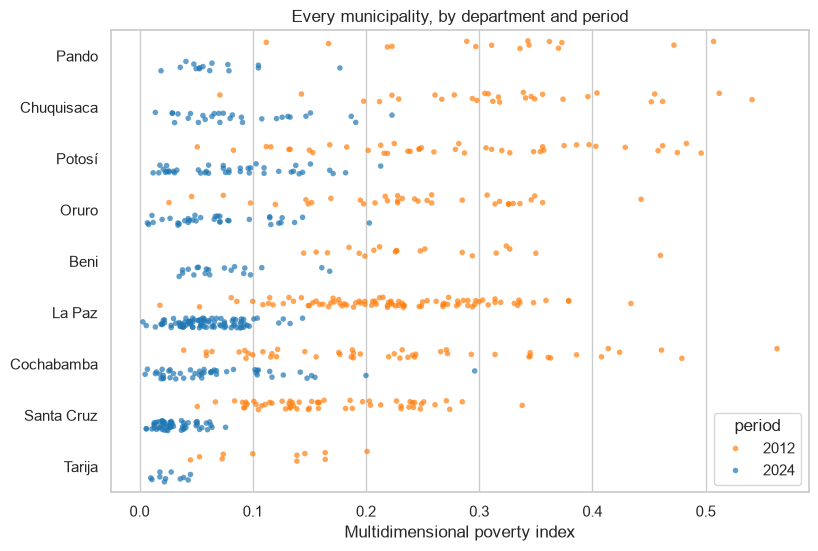

In [8]:
order = by_dep.sort_values(("median", 2012), ascending=False).index

fig, ax = plt.subplots(figsize=(9, 6))
sns.stripplot(data=long, x="sdg1_2_mpi", y="department", hue="period", order=order, palette=period_palette,
              dodge=True, size=4, jitter=0.2, alpha=0.7, ax=ax)
ax.set(xlabel=labels["sdg1_2_mpi"], ylabel="", title="Every municipality, by department and period")
plt.show()

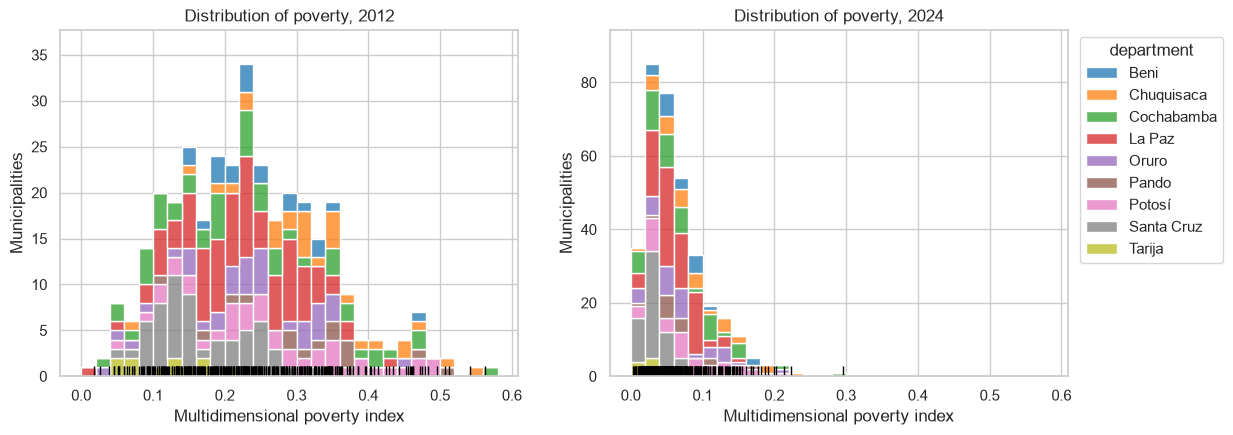

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)
for ax, year in zip(axes, YEARS):
    d = long[long["year"] == year]
    sns.histplot(data=d, x="sdg1_2_mpi", hue="department", hue_order=departments, palette=palette,
                 multiple="stack", binwidth=0.02, binrange=(0, 0.58), legend=(year == 2024), ax=ax)
    sns.rugplot(data=d, x="sdg1_2_mpi", color="black", height=0.03, ax=ax)
    ax.set(xlabel=labels["sdg1_2_mpi"], ylabel="Municipalities", title=f"Distribution of poverty, {year}")
sns.move_legend(axes[1], "upper left", bbox_to_anchor=(1.01, 1))
plt.show()

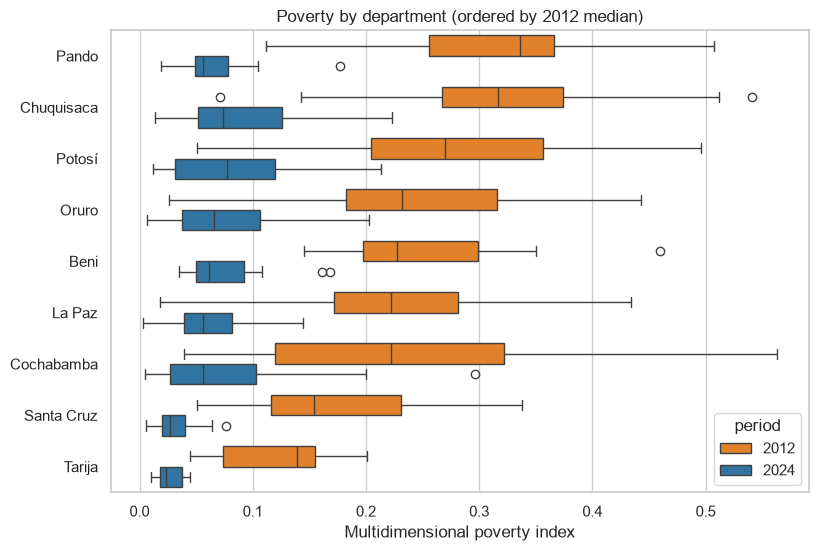

In [10]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.boxplot(data=long, x="sdg1_2_mpi", y="department", hue="period", order=order, palette=period_palette, ax=ax)
ax.set(xlabel=labels["sdg1_2_mpi"], ylabel="", title="Poverty by department (ordered by 2012 median)")
plt.show()

In [11]:
for year in YEARS:
    d = long[long["year"] == year]
    median = d["sdg1_2_mpi"].median()
    between = d.groupby("department")["sdg1_2_mpi"].transform("mean")
    share = between.var(ddof=0) / d["sdg1_2_mpi"].var(ddof=0)
    print(f"{year}: national median {median:.3f}; departments explain {share:.0%} of the variance; "
          f"units above 0.35: {(d['sdg1_2_mpi'] > 0.35).sum()}, above 0.15: {(d['sdg1_2_mpi'] > 0.15).sum()}")
pando = long[(long["department"] == "Pando")].pivot(index="name", columns="year", values="sdg1_2_mpi")
print(f"\nPando, 2012: {(pando[2012] >= 0.3).sum()} of {len(pando)} units at 0.30 or more; "
      f"below the national median: {', '.join(pando.index[pando[2012] < long.loc[long['year'] == 2012, 'sdg1_2_mpi'].median()])}")

2012: national median 0.227; departments explain 21% of the variance; units above 0.35: 43, above 0.15: 260
2024: national median 0.053; departments explain 18% of the variance; units above 0.35: 0, above 0.15: 17

Pando, 2012: 9 of 15 units at 0.30 or more; below the national median: Cobija, Porvenir, Puerto Rico, Santa Rosa


Departments differ, but municipalities differ much more within departments than the departments differ from one another: departmental means explain only 21% of the variance across municipalities in 2012 and 18% in 2024. In 2012 Cochabamba ran from 0.039 to the highest value in the country (0.563, TIOC-Raqaypampa), and Potosí from 0.051 to 0.496. Chuquisaca and Pando had the highest medians (0.317 and 0.336): 9 of Pando's 15 municipalities scored 0.30 or more, and only four (Cobija, Porvenir, Puerto Rico and Santa Rosa) were below the national median of 0.227. Tarija's poorest municipality scored 0.201. The 2012 distribution has a long right tail, with 43 units above 0.35.

By 2024 the whole distribution has shifted towards zero and narrowed: the national median is 0.053, no unit is above 0.35 and only 17 are above 0.15 (260 were in 2012). The order of the departments is broadly the same, with Chuquisaca and Potosí the poorest and Santa Cruz and Tarija (all below 0.08) the least poor. Pando's mean fell the most, from 0.315 to 0.068.

## 4. Change, 2012-2024

The same classes in both maps show the scale of the decline; the third map shows the change in MPI points.

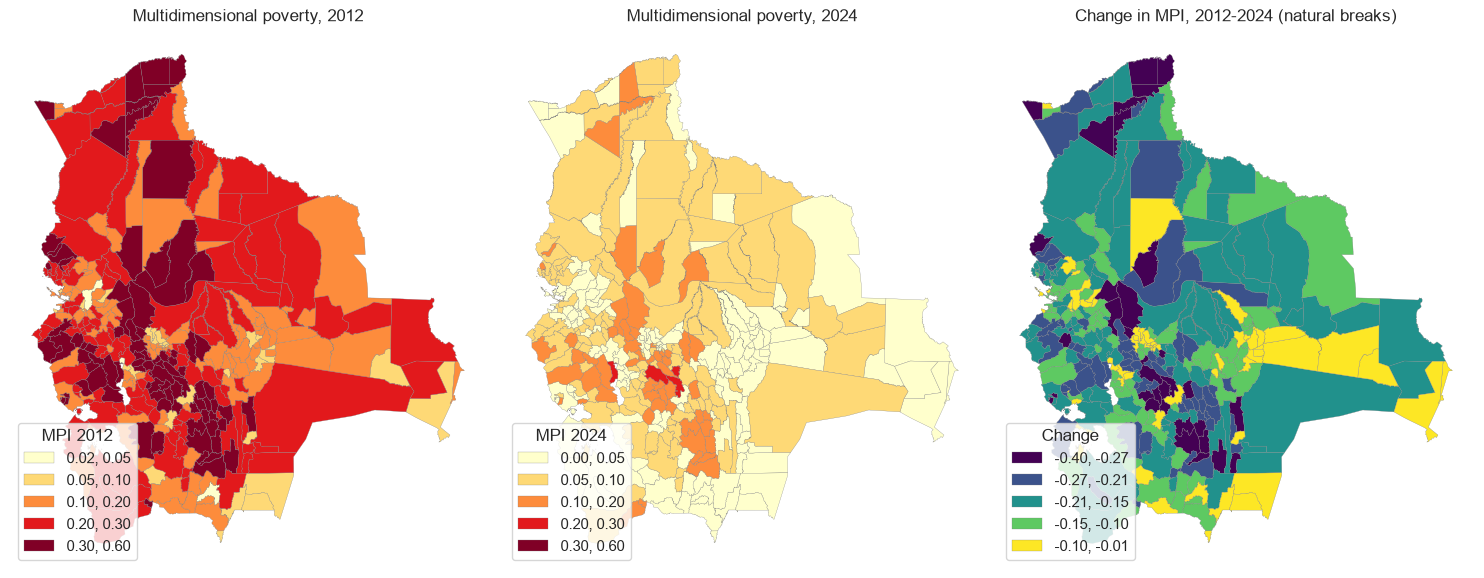

In [12]:
bins = {"bins": [0.05, 0.1, 0.2, 0.3, 0.6]}
fig, axes = plt.subplots(1, 3, figsize=(15, 6))
for ax, year in zip(axes, YEARS):
    gdf.plot(column=f"sdg1_2_mpi_{year}", scheme="user_defined", classification_kwds=bins, cmap="YlOrRd",
             edgecolor="grey", linewidth=0.2, legend=True, legend_kwds={"title": f"MPI {year}", "loc": "lower left"},
             ax=ax)
    ax.set_title(f"Multidimensional poverty, {year}")
gdf.plot(column="mpi_change", scheme="FisherJenks", k=5, cmap="viridis", edgecolor="grey", linewidth=0.2,
         legend=True, legend_kwds={"title": "Change", "loc": "lower left"}, ax=axes[2])
axes[2].set_title("Change in MPI, 2012-2024 (natural breaks)")
for ax in axes:
    ax.set_axis_off()
plt.tight_layout()
plt.show()

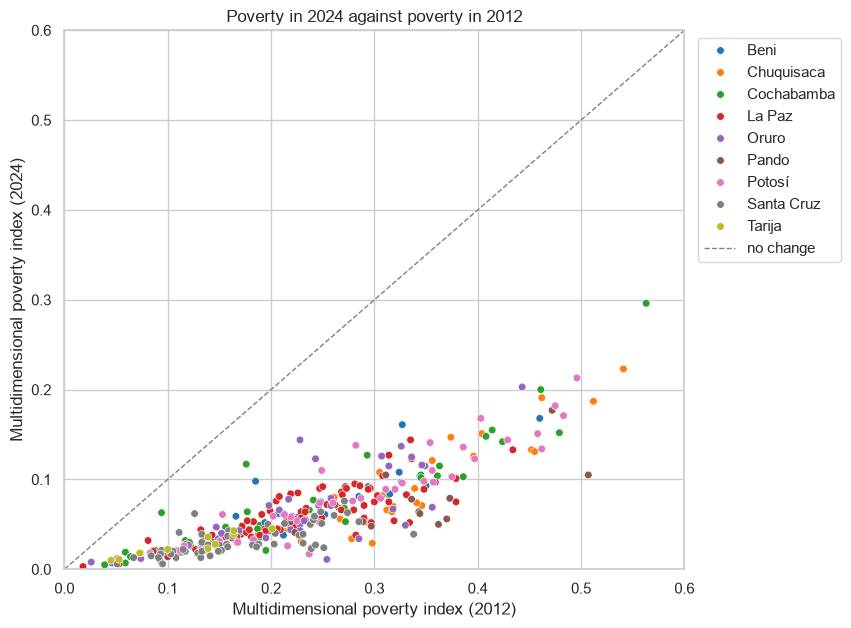

Units where poverty fell: 343 of 343
Correlation 2012-2024: 0.86 (rank: 0.86)
Slope of the change on the 2012 level: -0.641
MPI 2024 as a share of MPI 2012: median 0.24, from 0.04 to 0.67
Coefficient of variation: 2012 0.45, 2024 0.70


In [13]:
fig, ax = plt.subplots(figsize=(8, 7))
sns.scatterplot(data=gdf, x="sdg1_2_mpi_2012", y="sdg1_2_mpi_2024", hue="department", hue_order=departments,
                palette=palette, s=30, ax=ax)
ax.plot([0, 0.6], [0, 0.6], color="grey", ls="--", lw=1, label="no change")
ax.set(xlabel=labels["sdg1_2_mpi_2012"], ylabel=labels["sdg1_2_mpi_2024"], xlim=(0, 0.6), ylim=(0, 0.6),
       title="Poverty in 2024 against poverty in 2012")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.show()

fit = np.polyfit(gdf["sdg1_2_mpi_2012"], gdf["mpi_change"], 1)
ratio = gdf["sdg1_2_mpi_2024"] / gdf["sdg1_2_mpi_2012"]
print(f"Units where poverty fell: {(gdf['mpi_change'] < 0).sum()} of {len(gdf)}")
print(f"Correlation 2012-2024: {gdf['sdg1_2_mpi_2012'].corr(gdf['sdg1_2_mpi_2024']):.2f} "
      f"(rank: {gdf['sdg1_2_mpi_2012'].corr(gdf['sdg1_2_mpi_2024'], method='spearman'):.2f})")
print(f"Slope of the change on the 2012 level: {fit[0]:.3f}")
print(f"MPI 2024 as a share of MPI 2012: median {ratio.median():.2f}, "
      f"from {ratio.min():.2f} to {ratio.max():.2f}")
print(f"Coefficient of variation: 2012 {gdf['sdg1_2_mpi_2012'].std() / gdf['sdg1_2_mpi_2012'].mean():.2f}, "
      f"2024 {gdf['sdg1_2_mpi_2024'].std() / gdf['sdg1_2_mpi_2024'].mean():.2f}")

In [14]:
cols = ["name", "department", "sdg1_2_mpi_2012", "sdg1_2_mpi_2024", "mpi_change"]
print("Largest falls\n", gdf.nsmallest(5, "mpi_change")[cols].round(3).to_string(index=False))
print("\nSmallest falls\n", gdf.nlargest(5, "mpi_change")[cols].round(3).to_string(index=False))

Largest falls
       name department  sdg1_2_mpi_2012  sdg1_2_mpi_2024  mpi_change
      Sena      Pando            0.507            0.105      -0.402
Tinguipaya     Potosí            0.462            0.134      -0.328
    Alalay Cochabamba            0.479            0.152      -0.327
   Azurduy Chuquisaca            0.512            0.187      -0.325
    Presto Chuquisaca            0.455            0.131      -0.324

Smallest falls
                     name department  sdg1_2_mpi_2012  sdg1_2_mpi_2024  mpi_change
Nuestra Señora de La Paz     La Paz            0.018            0.003      -0.015
             Huachacalla      Oruro            0.026            0.008      -0.018
                  Tolata Cochabamba            0.094            0.063      -0.031
             Colcapirhua Cochabamba            0.039            0.005      -0.034
                  Tarija     Tarija            0.045            0.010      -0.035


Every unit is below the no-change line: poverty fell in all 343. Poorer municipalities fell the most in absolute terms (each 0.1 of MPI in 2012 goes with a further fall of 0.064), and the 2024 values are a median 24% of the 2012 values (from 4% to 67%). The ordering persists (correlation 0.86, rank correlation 0.86), so the poorest places of 2012 are mostly still the poorest. Absolute gaps narrowed (the standard deviation fell from 0.106 to 0.044), but relative gaps widened: the coefficient of variation rose from 0.45 to 0.70, because the least poor municipalities are now very close to zero. The largest fall was in Sena (Pando, -0.402), followed by Tinguipaya (Potosí), Alalay (Cochabamba), Azurduy and Presto (Chuquisaca), all about -0.33. The smallest falls were in places that had little poverty to lose (Nuestra Señora de La Paz, Huachacalla, Colcapirhua, Tarija), with Tolata (Cochabamba, 0.094 to 0.063) the exception.

## 5. Population and poverty

- Do the most populous municipalities tend to be less poor?

Population here is the census count of the same year (it replaces the WorldPop estimates the earlier version of this notebook used, which do not cover all 343 units). The 30 most populous municipalities in 2024, coloured by poverty:

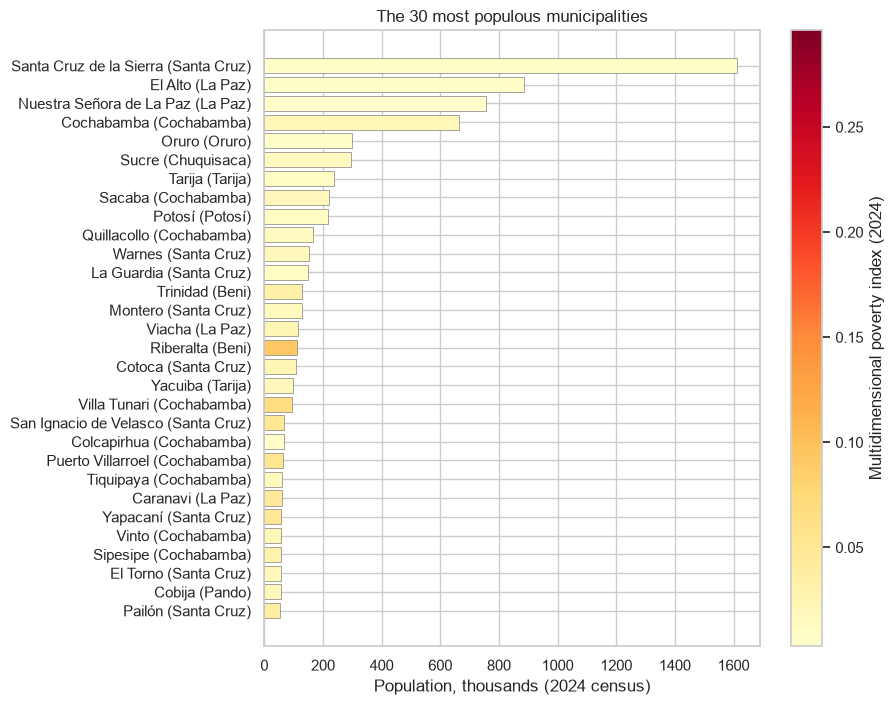

In [15]:
top = gdf.nlargest(30, "population_2024").sort_values("population_2024")
norm = plt.Normalize(gdf["sdg1_2_mpi_2024"].min(), gdf["sdg1_2_mpi_2024"].max())
cmap = plt.cm.YlOrRd

fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(top["name"] + " (" + top["department"] + ")", top["population_2024"] / 1e3,
        color=cmap(norm(top["sdg1_2_mpi_2024"])), edgecolor="grey", linewidth=0.5)
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, label=labels["sdg1_2_mpi_2024"])
ax.set(xlabel="Population, thousands (2024 census)", title="The 30 most populous municipalities")
plt.show()

The treemap nests municipalities within departments: the area of each tile is its 2024 population and its colour its 2024 poverty (hover for details; click a department to zoom in).

In [16]:
px.treemap(
    gdf, path=[px.Constant("Bolivia"), "department", "name"], values="population_2024",
    color="sdg1_2_mpi_2024", color_continuous_scale="YlOrRd",
    color_continuous_midpoint=np.average(gdf["sdg1_2_mpi_2024"], weights=gdf["population_2024"]),
    hover_data={"rank_mpi_2024": True}, labels=labels,
)

The same view for 2012, as a sunburst:

In [17]:
px.sunburst(
    gdf, path=["department", "name"], values="population_2012",
    color="sdg1_2_mpi_2012", color_continuous_scale="YlOrRd",
    color_continuous_midpoint=np.average(gdf["sdg1_2_mpi_2012"], weights=gdf["population_2012"]),
    labels={**labels, "population_2012": "Census population (2012)"},
)

2012: slope -0.031 MPI points per log point of population; correlation with log population: -0.34
2024: slope -0.009 MPI points per log point of population; correlation with log population: -0.23


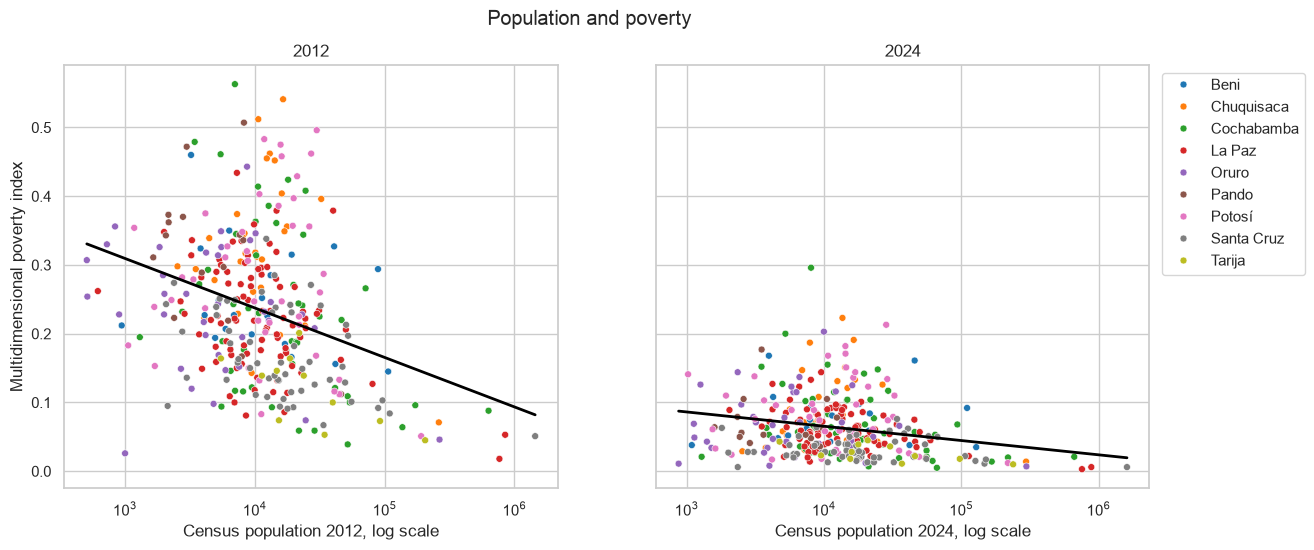

In [18]:
long["ln_pop"] = np.log(long["population"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
for ax, year in zip(axes, YEARS):
    d = long[long["year"] == year]
    sns.scatterplot(data=d, x="population", y="sdg1_2_mpi", hue="department", hue_order=departments,
                    palette=palette, s=25, legend=(year == 2024), ax=ax)
    fit = np.polyfit(d["ln_pop"], d["sdg1_2_mpi"], 1)
    xs = np.linspace(d["ln_pop"].min(), d["ln_pop"].max(), 100)
    ax.plot(np.exp(xs), np.polyval(fit, xs), color="black", lw=2)
    ax.set_xscale("log")
    ax.set(xlabel=f"Census population {year}, log scale", ylabel=labels["sdg1_2_mpi"], title=str(year))
    print(f"{year}: slope {fit[0]:.3f} MPI points per log point of population; "
          f"correlation with log population: {d['ln_pop'].corr(d['sdg1_2_mpi']):.2f}")
axes[1].legend(bbox_to_anchor=(1.01, 1), loc="upper left")
fig.suptitle("Population and poverty")
plt.show()

In [19]:
for year in YEARS:
    d = long[long["year"] == year]
    top10 = d.nlargest(10, "population")
    print(f"{year}: the 10 largest municipalities hold {top10['population'].sum() / d['population'].sum():.0%} "
          f"of the population; their highest MPI is {top10['sdg1_2_mpi'].max():.3f}. "
          f"Units with fewer than 20,000 people: {(d['population'] < 20_000).mean():.0%}. "
          f"Mean MPI: simple {d['sdg1_2_mpi'].mean():.3f}, "
          f"population-weighted {np.average(d['sdg1_2_mpi'], weights=d['population']):.3f}")

2012: the 10 largest municipalities hold 49% of the population; their highest MPI is 0.096. Units with fewer than 20,000 people: 76%. Mean MPI: simple 0.234, population-weighted 0.133
2024: the 10 largest municipalities hold 47% of the population; their highest MPI is 0.021. Units with fewer than 20,000 people: 73%. Mean MPI: simple 0.063, population-weighted 0.033


More populous municipalities tend to be less poor, in both periods. In 2012 the correlation with log population is -0.34, and a tenfold increase in population goes with an MPI about 0.07 lower (0.031 × ln 10). In 2024 the relation is weaker (correlation -0.23) and the same tenfold increase goes with an MPI only 0.02 lower (0.009 × ln 10), as poverty has fallen most where it was highest. The relationship is loose: municipalities with 5,000 to 20,000 people range from 0.074 to 0.563 in 2012.

Population and poverty are concentrated in different places. The ten largest municipalities hold 49% of the population in 2012 and 47% in 2024, and none has an MPI above 0.096 in 2012 or 0.021 in 2024, while about three quarters of the units have fewer than 20,000 people (76% in 2012, 73% in 2024). As a result the population-weighted mean MPI is about half the simple mean: 0.133 against 0.234 in 2012, and 0.033 against 0.063 in 2024. The typical Bolivian lives in a much less poor municipality than the typical municipality suggests.

## 6. Night-time lights and poverty

- Can night-time lights help us predict poverty?

Lights are available from 2012 to 2020, so we compare them with poverty in 2012, the year both were measured, on the **333 units** with lights. Side by side, the poverty map (three natural breaks) and the night-time lights map, with the ten units without lights in grey. Lights are mapped in quintiles: a few almost unlit municipalities are extreme outliers, and natural breaks would give them a class of their own.

units with lights and poverty: 333


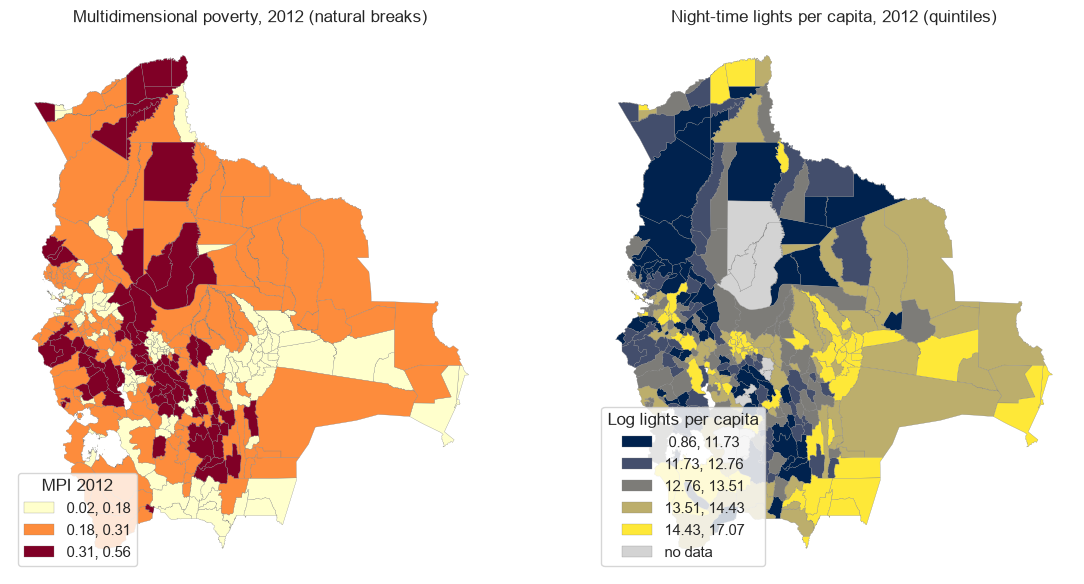

In [20]:
nl = gdf.dropna(subset=["ln_t400NTLpc"]).copy()
print(f"units with lights and poverty: {len(nl)}")

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
gdf.plot(column="sdg1_2_mpi_2012", scheme="FisherJenks", k=3, cmap="YlOrRd", edgecolor="grey", linewidth=0.2,
         legend=True, legend_kwds={"title": "MPI 2012", "loc": "lower left"}, ax=axes[0])
gdf.plot(column="ln_t400NTLpc", scheme="Quantiles", k=5, cmap="cividis", edgecolor="grey", linewidth=0.2,
         legend=True, legend_kwds={"title": "Log lights per capita", "loc": "lower left"},
         missing_kwds={"color": "lightgrey", "label": "no data"}, ax=axes[1])
axes[0].set_title("Multidimensional poverty, 2012 (natural breaks)")
axes[1].set_title("Night-time lights per capita, 2012 (quintiles)")
for ax in axes:
    ax.set_axis_off()
plt.tight_layout()
plt.show()

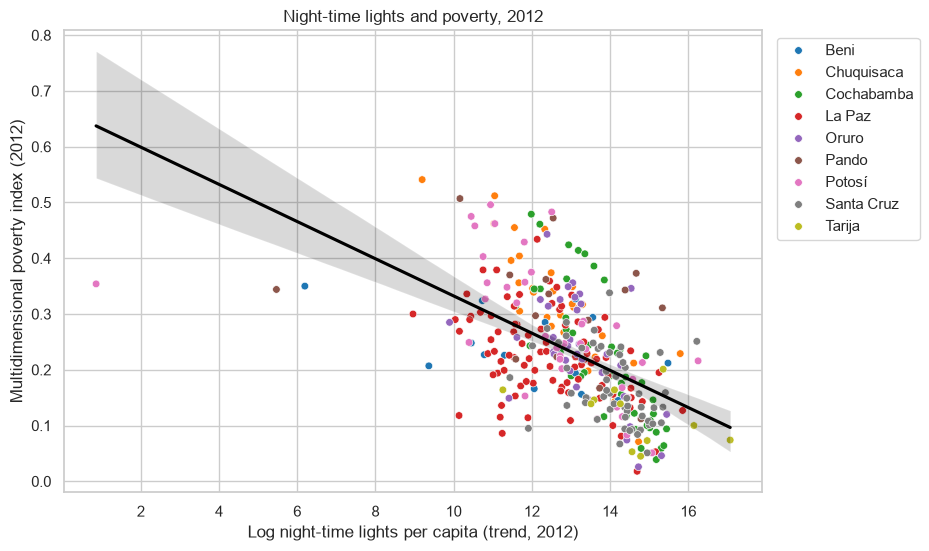

Slope: -0.033; correlation: -0.54; R-squared: 0.29


In [21]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=nl, x="ln_t400NTLpc", y="sdg1_2_mpi_2012", hue="department", hue_order=departments,
                palette=palette, s=30, ax=ax)
sns.regplot(data=nl, x="ln_t400NTLpc", y="sdg1_2_mpi_2012", scatter=False, color="black", ax=ax)
ax.set(xlabel=labels["ln_t400NTLpc"], ylabel=labels["sdg1_2_mpi_2012"], title="Night-time lights and poverty, 2012")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.show()

fit = np.polyfit(nl["ln_t400NTLpc"], nl["sdg1_2_mpi_2012"], 1)
r = nl["ln_t400NTLpc"].corr(nl["sdg1_2_mpi_2012"])
print(f"Slope: {fit[0]:.3f}; correlation: {r:.2f}; R-squared: {r**2:.2f}")

A few municipalities are almost unlit. Are they driving the result? The rank (Spearman) correlation and the correlation without them answer that:

In [22]:
dark = nl["ln_t400NTLpc"] < 7
print(nl.loc[dark, ["name", "department", "ln_t400NTLpc", "sdg1_2_mpi_2012", "population_2012"]].round(3).to_string(index=False))
print(f"\nSpearman correlation: {nl['ln_t400NTLpc'].corr(nl['sdg1_2_mpi_2012'], method='spearman'):.2f}")
print(f"Pearson correlation without them: {nl.loc[~dark, 'ln_t400NTLpc'].corr(nl.loc[~dark, 'sdg1_2_mpi_2012']):.2f}")

       name department  ln_t400NTLpc  sdg1_2_mpi_2012  population_2012
 Exaltación       Beni         6.194            0.350             6362
San Lorenzo      Pando         5.467            0.344             7652
   Mojinete     Potosí         0.856            0.354             1180

Spearman correlation: -0.60
Pearson correlation without them: -0.57


Do the lights of 2012 also anticipate poverty in 2024, and do the latest lights (2020) relate to it?

In [23]:
nl = nl.merge(geo.load("ntl", variables="ln_t400NTLpc", years=2020)[["geo_id", "ln_t400NTLpc"]]
              .rename(columns={"ln_t400NTLpc": "ln_t400NTLpc_2020"}), on="geo_id")
print(f"Lights 2012 and MPI 2024: {nl['ln_t400NTLpc'].corr(nl['sdg1_2_mpi_2024']):.2f}")
print(f"Lights 2020 and MPI 2024: {nl['ln_t400NTLpc_2020'].corr(nl['sdg1_2_mpi_2024']):.2f}")
print(f"Lights 2012 and the change in MPI: {nl['ln_t400NTLpc'].corr(nl['mpi_change']):.2f}")

Lights 2012 and MPI 2024: -0.49
Lights 2020 and MPI 2024: -0.50
Lights 2012 and the change in MPI: 0.50


Brighter municipalities were less poor. Across the 333 units with lights, the correlation between lights per capita and the MPI in 2012 is -0.54, so lights alone account for 29% of the variation in poverty. An increase of one log point in lights per capita goes with an MPI 0.033 lower.

Three municipalities are almost unlit (Mojinete in Potosí, San Lorenzo in Pando and Exaltación in Beni). They do not drive the result: without them the correlation is -0.57, and the rank correlation is -0.60.

The relation carries over to 2024 almost as strongly: the lights of 2012 correlate -0.49 with poverty in 2024, and the lights of 2020 -0.50. Brighter municipalities saw smaller falls in poverty (correlation 0.50 between lights and the change), largely because they had less poverty to lose.

- How heterogeneous is the relationship between poverty and night-time lights across departments?

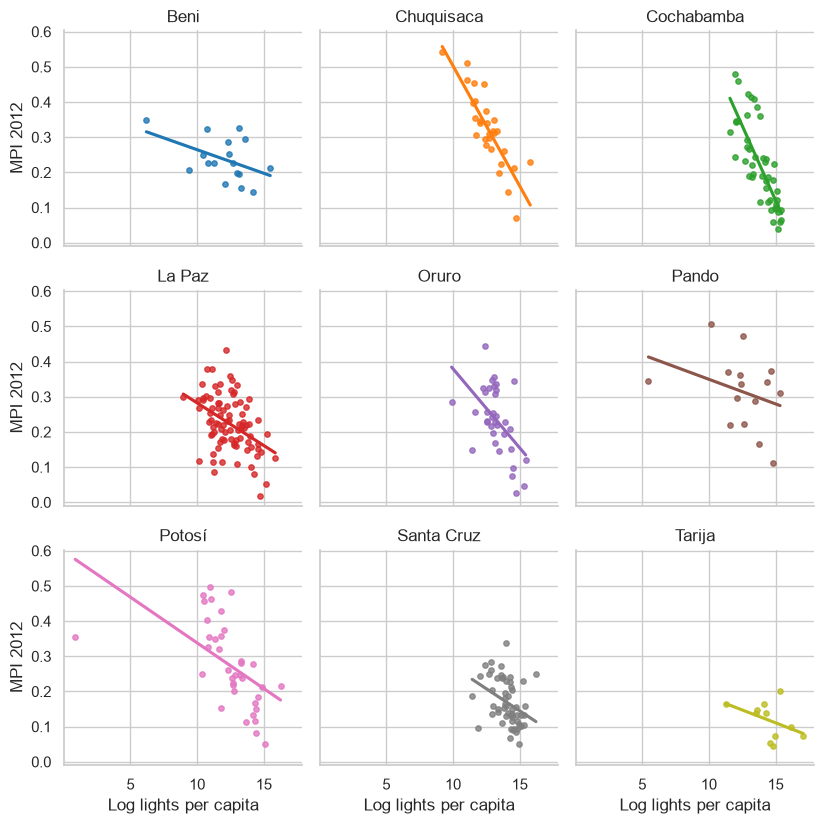

In [24]:
g = sns.lmplot(data=nl, x="ln_t400NTLpc", y="sdg1_2_mpi_2012", col="department", col_order=departments,
               hue="department", hue_order=departments, palette=palette, col_wrap=3, height=2.8,
               scatter_kws={"s": 15}, ci=None)
g.set_axis_labels("Log lights per capita", "MPI 2012")
g.set_titles("{col_name}")
plt.show()

In [25]:
def fit_by_group(d):
    slope = np.polyfit(d["ln_t400NTLpc"], d["sdg1_2_mpi_2012"], 1)[0]
    return pd.Series({"municipalities": len(d), "slope": slope,
                      "correlation": d["ln_t400NTLpc"].corr(d["sdg1_2_mpi_2012"])})

print("Potosí without Mojinete:", fit_by_group(nl[(nl["department"] == "Potosí") & (nl["name"] != "Mojinete")]).round(3).to_dict())
nl.groupby("department")[["ln_t400NTLpc", "sdg1_2_mpi_2012"]].apply(fit_by_group).round(3).sort_values("slope")

Potosí without Mojinete: {'municipalities': 36.0, 'slope': -0.058, 'correlation': -0.738}


,municipalities,slope,correlation
department,,,
Cochabamba,46.0,-0.085,-0.791
Chuquisaca,29.0,-0.068,-0.849
Oruro,35.0,-0.045,-0.518
Potosí,37.0,-0.026,-0.536
Santa Cruz,56.0,-0.025,-0.365
La Paz,87.0,-0.024,-0.426
Tarija,11.0,-0.015,-0.429
Pando,15.0,-0.014,-0.321
Beni,17.0,-0.013,-0.465


The relationship is negative in all nine departments, but its strength varies. It is steepest and tightest in Cochabamba (slope -0.085, correlation -0.79) and Chuquisaca (-0.068, -0.85), where lights separate the poorer rural municipalities from the rest well. It is weakest in Pando (correlation -0.32) and Santa Cruz (-0.37), and flattest in Beni, Pando and Tarija (slopes between -0.013 and -0.015); in Tarija poverty is uniformly low. Potosí's slope (-0.026) is flattened by Mojinete, its almost unlit outlier: without it the slope is -0.058 and the correlation -0.74.

## Summary

- Multidimensional poverty fell in all 343 municipalities and indigenous autonomies between 2012 and 2024: the municipal mean went from 0.234 to 0.063 (median 0.227 to 0.053), and the population-weighted national mean from 0.133 to 0.033.
- In both periods poverty varies much more within departments than between them (departments explain about a fifth of the variance). Chuquisaca, Pando and Potosí had the poorest municipalities in 2012; Chuquisaca, Potosí and Beni in 2024. Tarija and Santa Cruz are the least poor in both. TIOC-Raqaypampa is the poorest unit and Nuestra Señora de La Paz the least poor in both periods.
- Poorer municipalities fell most in absolute terms and the ordering persisted (correlation 0.86): absolute gaps narrowed, relative gaps widened (coefficient of variation 0.45 to 0.70).
- Larger municipalities are less poor (correlation with log population -0.34 in 2012, -0.23 in 2024). The large cities have low poverty and hold close to half the population, so the population-weighted MPI is about half the municipal average.
- Night-time lights per capita are a stronger predictor (correlation -0.54 in 2012, on the 333 units with lights), robust to the few almost unlit municipalities, negative in every department, and still -0.50 between the lights of 2020 and poverty in 2024.
- The maps show that poverty and lights are spatially clustered. The companion notebooks [`esda`](https://colab.research.google.com/github/quarcs-lab/geo4bolivia/blob/main/notebooks/esda.ipynb) and [`esda_dependence`](https://colab.research.google.com/github/quarcs-lab/geo4bolivia/blob/main/notebooks/esda_dependence.ipynb) measure that clustering with spatial weights, Moran's I and LISA.